In [1]:
from xenonnt_plot_style import XENONPlotStyle as xps
xps.use('xenonnt')

In [2]:
import os
import numpy as np
import matplotlib.pyplot as plt

from utils import read_rga_file, get_t0, get_integral, get_partial_pressure, get_kr_concentration

In [3]:
folder = '../../Documents/RGAData/PressurevsTime'
# folder = '../rga'

filenames = [
    'PressurevsTime-20261102-171546-393.txt',
    'PressurevsTime-20261106-100455-776.txt',
    'PressurevsTime-20261106-103217-236.txt',
    'PressurevsTime-20261106-114035-676.txt',
]

masses = [87, 28, 40, 62, 84]

In [4]:
# Calibration inputs of each file, passed to get_kr_concentration
# TODO: fill in the measured values; all four are the defaults (notes/202611.tex) for now
calibrations = [
    dict(delta_v=0.0842, n_expansion=3, temperature=292, recycler_pressure=14.8),
    dict(delta_v=0.0842, n_expansion=3, temperature=292, recycler_pressure=14.8),
    dict(delta_v=0.0842, n_expansion=3, temperature=292, recycler_pressure=14.8),
    dict(delta_v=0.0842, n_expansion=3, temperature=292, recycler_pressure=14.8),
]

In [5]:
# Sample partial pressure of AMU 84 (Sec. 1) and Kr mole fraction (Sec. 2) of each file
P, P_err = np.empty(len(filenames)), np.empty(len(filenames))
x_kr, x_kr_err = np.empty(len(filenames)), np.empty(len(filenames))

for i, (filename, calibration) in enumerate(zip(filenames, calibrations)):
    rga = read_rga_file(os.path.join(folder, filename))
    t0 = get_t0(rga['t'], rga[28])
    P[i], P_err[i] = get_partial_pressure(rga, t0, mass=84)
    x_kr[i], x_kr_err[i] = get_kr_concentration(**calibration)

    print(
        f'{filename}: x_Kr = {x_kr[i] * 1e15:.0f} +- {x_kr_err[i] * 1e15:.0f} ppq, '
        f'P_sample = {P[i]:.3e} +- {P_err[i]:.1e} Torr'
    )

PressurevsTime-20261102-171546-393.txt: x_Kr = 1300 +- 200 ppq, P_sample = 7.289e-11 +- 8.0e-13 Torr
PressurevsTime-20261106-100455-776.txt: x_Kr = 1300 +- 200 ppq, P_sample = 4.058e-11 +- 5.2e-13 Torr
PressurevsTime-20261106-103217-236.txt: x_Kr = 1300 +- 200 ppq, P_sample = 6.051e-11 +- 3.0e-12 Torr
PressurevsTime-20261106-114035-676.txt: x_Kr = 1300 +- 200 ppq, P_sample = 5.082e-11 +- 3.9e-13 Torr


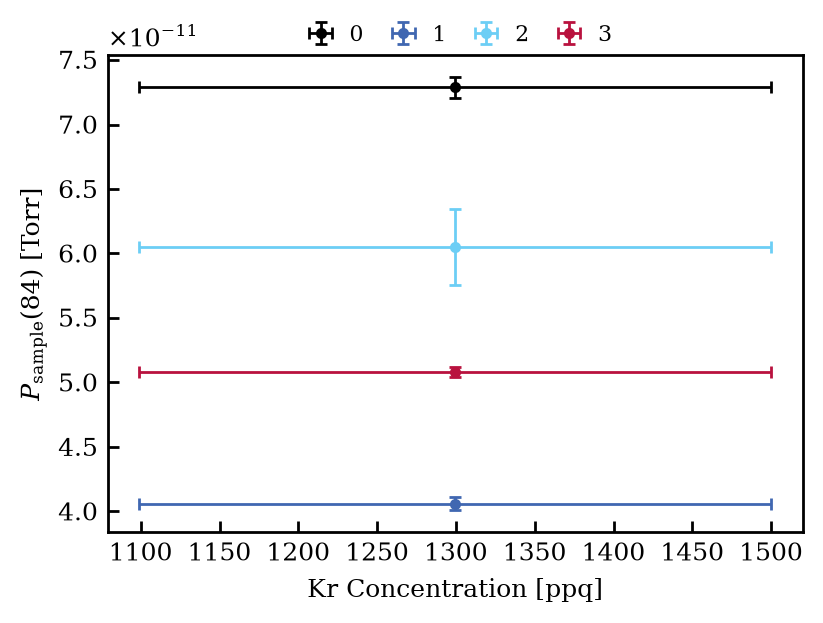

In [6]:
fig, ax = plt.subplots(1, 1, figsize=(4, 3))

for i in range(len(filenames)):
    ax.errorbar(
        x_kr[i] * 1e15, P[i],
        xerr=x_kr_err[i] * 1e15, yerr=P_err[i],
        marker='o', linestyle='none', capsize=2, label=i,
    )

ax.legend(ncols=len(filenames))
ax.set_xlabel('Kr Concentration [ppq]')
ax.set_ylabel('$P_\\mathrm{sample}$(84) [Torr]')

plt.show()